<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Serving Maps: Tiles and OGC APIs

Notebook 08_04 put data *inside* web pages. That works for one map and one reader, but not for an
organisation that publishes data many people and programs use. They need a **service**: an address
on the web that answers requests for map tiles or features, so a browser, QGIS, ArcGIS, a Python
script or another server can each ask for just the part they need. This notebook builds and tests
such services with `geolattice.web`:

- **raster tiles**, pre-rendered (static) and rendered on request (dynamic), from local files and
  from a Sentinel-2 Cloud-Optimized GeoTIFF on AWS;
- an **OGC API: Features** service for Bangladesh boundaries, arsenic samples and California PM2.5
  measurements, read back by GDAL, GeoPandas and OWSLib;
- **PMTiles** vector tiles served as one static file, shown with MapLibre.

Everything runs inside this notebook on `127.0.0.1`; Notebook 08_10 covers deployment.



### Learning objectives

1. Name the main map-service standards (WMS, WMTS, XYZ/TMS, TileJSON, OGC API: Features, Tiles and
   Maps, vector tiles, PMTiles) and what each one delivers.
2. Decide between static and dynamic tiles from storage, latency and data-transfer numbers.
3. Serve raster tiles and an OGC API: Features service with `geolattice.web.create_app`, and run it in
   the background with `start_server`.
4. Query features with paging, bounding boxes, attribute filters and time (`datetime`).
5. Consume the service from GDAL, GeoPandas, OWSLib and a web map, as other users would.
6. Publish vector tiles as a single PMTiles file and display them with MapLibre.



### Data

| Data | Source |
|---|---|
| Sentinel-2 NDVI and band stacks over Syracuse, NY (July 2025) | `Data/00_shared/data_web_cloud_gis/08_01_outputs/`, `s2_syracuse_2025/` (Notebook 08_01) |
| Sentinel-2 true-colour COG of tile 18TVN, 23 July 2025, on AWS | Earth Search (`sentinel-cogs` bucket), read remotely |
| District poverty table of Bangladesh | `Data/00_shared/data_web_cloud_gis/08_03_outputs/districts.gpkg` (Notebook 08_03) |
| Union boundaries of Bangladesh (5,160) and arsenic at 263 rice fields | `Data/00_shared/vector_data/Bangladesh/` |
| Daily PM2.5 at 163 California monitoring sites, 2025 (59,566 rows) | `Data/00_shared/data_spatial_stat/CA_pm25_2025.csv` |
| New York counties | `Data/00_shared/vector_data/USA/NY_County_GCS.shp` |

Run Notebooks 08_01 and 08_03 first. The extra clients are installed with
`pip install owslib pmtiles httpx`.



### Contents

1. Setup
2. Map-service standards
3. Static tiles: pre-rendered pyramids
4. Dynamic tiles: rendering on request
5. An OGC API: Features service
6. Using the service from GDAL, GeoPandas and OWSLib
7. One server, many requests
8. Vector tiles as one file: PMTiles
9. From a notebook to production
10. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `owslib`, `pmtiles`, which no GeoLattice option installs: `pip install owslib pmtiles`.

In [1]:
# Setup: imports, paths, HTTP helper, and web_ready geometry simplifier
%matplotlib inline
import json
import shutil
import threading
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import httpx
import matplotlib.pyplot as plt
from IPython.display import IFrame, display
from osgeo import gdal, ogr
from owslib.ogcapi.features import Features
import pmtiles.reader as pmr

import geolattice
import geolattice.web as web
from geolattice.vector import write_pmtiles

gdal.UseExceptions()
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
BD = DATA / "00_shared" / "vector_data" / "Bangladesh"
WEB = DATA / "00_shared" / "data_web_cloud_gis"
OUT = WEB / "08_05_outputs"
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)
for needed in [WEB / "08_03_outputs" / "districts.gpkg", WEB / "08_01_outputs" / "ndvi_syracuse_20250723.tif",
               WEB / "08_01_outputs" / "stack_deflate_2.tif"]:
    if not needed.exists():
        raise FileNotFoundError(f"{needed} is missing: run Notebooks 08_01 and 08_03 first")

http = httpx.Client(timeout=300)

def get(url, show=True, **params):
    "GET a URL; print status, type and size; return the response."
    t0 = time.perf_counter()
    r = http.get(url, params=params or None)
    if show:
        print(f"{r.status_code} {r.headers.get('content-type', '-'):38s} {len(r.content):>11,} bytes "
              f"{(time.perf_counter() - t0) * 1000:7.0f} ms  {r.url.path}{'?' + r.url.query.decode() if r.url.query else ''}")
    return r

def web_ready(gdf, tolerance=250, digits=5):
    "Coverage-simplify in UTM 46N and round coordinates (Notebook 08_04)."
    g = gdf.to_crs(32646)
    s = gpd.GeoSeries(shapely.coverage_simplify(g.geometry.values, tolerance), crs=32646).to_crs(4326)
    return gpd.GeoDataFrame(gdf.drop(columns="geometry"),
                            geometry=shapely.set_precision(s.values, 10.0 ** -digits), crs=4326)

print("geolattice", geolattice.__version__, "| GDAL", gdal.__version__, "| outputs:", OUT)


geolattice 0.3.11 | GDAL 3.13.3 | outputs: ../../../data/data_web_cloud_gis/08_05_outputs


## Map-service standards

| Standard | Request | Returns | Typical use |
|---|---|---|---|
| **WMS** (OGC Web Map Service, 1999) | A bounding box, size and layers | One rendered image per request | Classic GIS servers; any extent, no caching |
| **WMTS** (OGC, 2010) / **TMS** | A tile in a fixed grid | Pre-cut image tiles | Cached basemaps in desktop GIS |
| **XYZ tiles** (`/{z}/{x}/{y}.png`) | Zoom, column, row in Web Mercator | 256 × 256 image tiles | Every web map; de facto standard |
| **TileJSON** | `tilejson.json` | Tile URL template, bounds, zoom range | Lets a client configure itself |
| **Vector tiles (MVT)** | A tile in the XYZ grid | Clipped, simplified vector features (Protobuf) | Styled in the browser; MapLibre, Mapbox |
| **PMTiles** | HTTP range requests on one file | Vector or raster tiles plus an index | Tile sets without a tile server |
| **OGC API: Features** (2019) | `/collections/{id}/items?bbox=...` | GeoJSON features, paged | Data access for programs, QGIS, ArcGIS |
| **OGC API: Tiles / Maps** (2022-23) | `/collections/{id}/tiles/...`, `/map` | Tiles / map images with metadata | Modern successors of WMTS and WMS |

The OGC API family replaces the XML-based W*S services with resource URLs, JSON and an
**OpenAPI** description, the same style as any modern web API.

Tiles can be **static** (rendered once, stored as files, served by any web server or a CDN) or
**dynamic** (rendered from the source data when requested). `geolattice.web` does both:
`make_xyz_tiles` writes static pyramids, and `create_app` builds a server for dynamic tiles and
OGC API: Features (Starlette, run with uvicorn).

## Static tiles: pre-rendered pyramids

Each zoom level has four times as many tiles as the one before. Before deciding to pre-render, count
the tiles an area needs:

In [2]:
# Count XYZ tiles needed for Syracuse NDVI vs all of Bangladesh across zooms
def tile_count(bounds, z):
    west, south, east, north = bounds
    a, b = web.lonlat_to_tile(west, north, z), web.lonlat_to_tile(east, south, z)
    return (b.x - a.x + 1) * (b.y - a.y + 1)

ndvi_path = WEB / "08_01_outputs" / "ndvi_syracuse_20250723.tif"
syracuse = web.raster_web_info(ndvi_path)["bounds"]
bangladesh = (88.0, 20.6, 92.7, 26.7)
counts = pd.DataFrame({"zoom": range(6, 19)})
counts["m per pixel (24°N)"] = [round(web.tile_resolution(z, latitude=24), 1) for z in counts.zoom]
counts["Syracuse NDVI tiles"] = [tile_count(syracuse, z) for z in counts.zoom]
counts["Bangladesh tiles"] = [tile_count(bangladesh, z) for z in counts.zoom]
counts["Bangladesh, cumulative"] = counts["Bangladesh tiles"].cumsum()
counts.set_index("zoom").T


zoom,6,7,8,9,10,11,12,13,14,15,16,17,18
m per pixel (24°N),2234.5,1117.3,558.6,279.3,139.7,69.8,34.9,17.5,8.7,4.4,2.2,1.1,0.5
Syracuse NDVI tiles,1.0,2.0,2.0,2.0,2.0,4.0,9.0,25.0,81.0,289.0,1088.0,4284.0,16740.0
Bangladesh tiles,4.0,6.0,24.0,77.0,280.0,1092.0,4158.0,16416.0,65360.0,260832.0,1040398.0,4157451.0,16616672.0
"Bangladesh, cumulative",4.0,10.0,34.0,111.0,391.0,1483.0,5641.0,22057.0,87417.0,348249.0,1388647.0,5546098.0,22162770.0


In [3]:
# Build a static NDVI XYZ pyramid (zooms 9-14) with a simple HTML viewer
t0 = time.perf_counter()
pyramid = web.make_xyz_tiles(ndvi_path, OUT / "ndvi_tiles", zooms=range(9, 15), colormap="RdYlGn",
                             rescale=(-0.1, 0.9), viewer=True, name="NDVI 23 July 2025")
seconds = time.perf_counter() - t0
files = list((OUT / "ndvi_tiles").rglob("*.png"))
mean_kb = np.mean([f.stat().st_size for f in files]) / 1e3
print(f"{pyramid['tiles']} tiles ({pyramid['empty']} empty skipped) at zooms 9-14 in {seconds:.1f} s, "
      f"{seconds / pyramid['tiles'] * 1000:.0f} ms per tile; mean tile {mean_kb:.0f} kB")
print(json.dumps(pyramid["tilejson"], indent=1)[:600])


117 tiles (6 empty skipped) at zooms 9-14 in 2.6 s, 23 ms per tile; mean tile 95 kB
{
 "tilejson": "3.0.0",
 "name": "NDVI 23 July 2025",
 "tiles": [
  "{z}/{x}/{y}.png"
 ],
 "scheme": "xyz",
 "minzoom": 9,
 "maxzoom": 14,
 "bounds": [
  -76.2224674,
  42.9781455,
  -76.0379568,
  43.1018497
 ],
 "center": [
  -76.130212109571,
  43.03999761700632,
  9
 ]
}


Rendering the Syracuse NDVI at zooms 9-14 made 117 tiles in 2.6 s (23 ms per tile, 95 kB on average).
For a city-sized raster that is trivial. For Bangladesh the count explodes: 87,417 tiles up to zoom 14,
1.39 million up to zoom 16 and 22.2 million up to zoom 18. At the same 23 ms and 95 kB per tile,
the full pyramid to zoom 18 would take about six days of rendering and 2.1 TB of storage, much of it for tiles
nobody ever views (the bounding box also covers sea and India). Pre-rendering suits small areas,
limited zooms, or the zoom levels everyone sees; deeper zooms are rendered on demand.

A pyramid is a folder of files, so any static web server can publish it. `web.static_server` serves
it here, with HTTP range support and counters; in production the same folder goes to object storage
(S3, Azure Blob, Google Cloud Storage) behind a CDN, or to GitHub Pages.

In [4]:
# Serve prebuilt tiles, time zoom-14 requests, and open the viewer
static = web.static_server(OUT)
center = web.raster_web_info(ndvi_path)["center"]
tiles14 = [t for t in web.tiles_for_bounds(*syracuse, 14) if (OUT / "ndvi_tiles" / str(t.z) / str(t.x) / f"{t.y}.png").exists()][:30]
static_ms = []
for t in tiles14:
    t0 = time.perf_counter()
    r = http.get(f"{static.url}/ndvi_tiles/{t.z}/{t.x}/{t.y}.png")
    static_ms.append((time.perf_counter() - t0) * 1000)
print(f"static tiles: {len(static_ms)} requests, median {np.median(static_ms):.1f} ms, max {max(static_ms):.1f} ms")
get(f"{static.url}/ndvi_tiles/tilejson.json")
display(IFrame(f"{static.url}/ndvi_tiles/index.html", width="100%", height=420))


static tiles: 30 requests, median 3.0 ms, max 6.1 ms
200 application/json                               302 bytes       3 ms  /ndvi_tiles/tilejson.json


The pyramid folder also holds `index.html`, a Leaflet viewer written by `make_xyz_tiles`, and
`tilejson.json`, which tells clients the URL template, bounds and zoom range.

## Dynamic tiles: rendering on request

A dynamic tile server keeps only the source raster and renders each tile when it is asked for:
it reads the pixels under the tile, warps them to Web Mercator, applies a colour map and encodes a
PNG. `create_app` builds such a server. `start_server` runs it in the background, so the notebook
can keep working while it serves (on a real server you would use `web.serve(app)` or `uvicorn`).

In [5]:
# Start a dynamic tile server and compare latency to static PNG tiles
tile_app = web.create_app(rasters={"ndvi": {"path": ndvi_path, "colormap": "RdYlGn", "rescale": (-0.1, 0.9)}},
                          title="Syracuse NDVI")
tile_server = web.start_server(tile_app)
print(tile_server)
for path in ["/tiles", "/tiles/ndvi/tilejson.json"]:
    get(tile_server.url + path)

dynamic_ms = []
for t in tiles14:
    t0 = time.perf_counter()
    r = http.get(f"{tile_server.url}/tiles/ndvi/{t.z}/{t.x}/{t.y}.png")
    dynamic_ms.append((time.perf_counter() - t0) * 1000)
print(f"dynamic tiles: {len(dynamic_ms)} requests, median {np.median(dynamic_ms):.1f} ms, max {max(dynamic_ms):.1f} ms;"
      f" Cache-Control: {r.headers['cache-control']}")
empty = get(f"{tile_server.url}/tiles/ndvi/14/0/0.png")


BackgroundServer(http://127.0.0.1:34797)
200 application/json                               228 bytes       2 ms  /tiles
200 application/json                               241 bytes       1 ms  /tiles/ndvi/tilejson.json


dynamic tiles: 30 requests, median 33.6 ms, max 84.0 ms; Cache-Control: public, max-age=3600
204 -                                                0 bytes       2 ms  /tiles/ndvi/14/0/0.png


Static tiles came back in a median 3.0 ms: the server only reads a file. The dynamic server needed a
median 34 ms per tile to read, warp, colour and encode it, about ten times longer, but it stores
nothing beyond the 8.6 MB source raster. A tile outside the raster returns **204 No Content**, which
map libraries treat as an empty tile, and every tile carries `Cache-Control: public, max-age=3600`
so browsers and CDNs can reuse it.

### Why the source must be a Cloud-Optimized GeoTIFF

A tile server rarely has the raster on its own disk; it reads it from object storage. Then the file
layout decides how many bytes each tile costs. We serve two versions of the same Sentinel-2 band
stack over HTTP, the plain tiled GeoTIFF downloaded in 08_01 (12 MB, no overviews) and the COG made
from it (16 MB, with overviews), and count what one tile at each zoom transfers.

The file server runs in a **separate process** (`subprocess=True`). rasterio, which `render_tile`
uses, ships its own GDAL and holds Python's global interpreter lock while it waits for the network,
so it would deadlock against a file server running in this same process.

In [6]:
# Compare plain GeoTIFF vs COG byte reads when tiles are rendered on the fly
files_srv = web.static_server(WEB, subprocess=True)
layers = {"plain": "s2_syracuse_2025/S2C_18TVN_20250723_0_L2A/stack.tif",
          "cog": "08_01_outputs/stack_deflate_2.tif"}
for name, rel in layers.items():
    size = (WEB / rel).stat().st_size
    import rasterio
    with rasterio.open(WEB / rel) as src:
        print(f"{name:5s}: {size / 1e6:5.1f} MB, blocks {src.block_shapes[0]}, overviews {src.overviews(1) or 'none'}")

cog_app = web.create_app(rasters={n: {"path": f"{files_srv.url}/{rel}", "bands": [3, 2, 1], "rescale": (0, 2500)}
                                  for n, rel in layers.items()})
import os
os.environ["CPL_VSIL_CURL_NON_CACHED"] = f"/vsicurl/{files_srv.url}"     # measure each tile from scratch
rows = []
with web.start_server(cog_app) as srv:
    for name in layers:
        for z in range(10, 15):
            t = web.lonlat_to_tile(-76.14, 43.04, z)
            files_srv.reset()
            t0 = time.perf_counter()
            r = http.get(f"{srv.url}/tiles/{name}/{z}/{t.x}/{t.y}.png")
            ms = (time.perf_counter() - t0) * 1000
            s = files_srv.stats
            rows.append({"file": name, "zoom": z, "HTTP requests": s["requests"], "MB read": round(s["bytes"] / 1e6, 2),
                         "ms": round(ms)})
del os.environ["CPL_VSIL_CURL_NON_CACHED"]
cog_table = pd.DataFrame(rows).pivot(index="zoom", columns="file", values=["MB read", "HTTP requests"])
cog_table


plain:  12.2 MB, blocks (256, 256), overviews none
cog  :  15.9 MB, blocks (512, 512), overviews [2, 4]


MB read        HTTP requests      
file     cog  plain           cog plain
zoom                                   
10      0.82  10.03           5.0   7.0
11      0.82   6.90           5.0  23.0
12      2.16   6.39           6.0  19.0
13      3.24   1.66           4.0  11.0
14      1.66   0.52           3.0   7.0

At zoom 10, where one tile covers the whole image, the plain GeoTIFF had to read **10.0 MB of its
12.2 MB** (every full-resolution pixel under the tile) in 7 requests, while the COG read **0.82 MB** from
its 4× overview. The COG kept using overviews down to zoom 12. At zooms 13-14, where tiles are close
to full resolution, the COG read more (3.24 and 1.66 MB against 1.66 and 0.52 MB): its blocks are
512 × 512 pixels instead of 256 × 256, so each block it fetches covers more ground than one small tile
needs. Smaller internal blocks favour high-zoom tiles; overviews are what make zoomed-out views
affordable. Note also that the plain file needed up to 23 HTTP requests per tile, the COG at most 6.

While building this comparison we found and fixed two problems in `geolattice.web`: `render_tile` warped
from full resolution even when the COG had overviews (a zoomed-out tile of a large remote COG took
many seconds), and a single `rescale` pair given as a list was rejected for RGB rasters only when the
first tile was requested. Tiles now read from the coarsest suitable overview, and `create_app` checks
the band and rescale settings when it starts.

### Straight from the cloud

The same server can render tiles from a COG anywhere on the internet. Here it serves the
true-colour image of Sentinel-2 tile 18TVN (110 × 110 km) directly from Earth Search's AWS bucket,
with no download. Each request is timed twice: cold, and again once GDAL has cached the blocks.

In [7]:
# Render tiles from a remote Sentinel-2 COG; time cold vs warm requests
TCI = ("https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/18/T/VN/2025/7/"
       "S2C_18TVN_20250723_0_L2A/TCI.tif")
try:
    t0 = time.perf_counter()
    remote_app = web.create_app(rasters={"s2": {"path": TCI, "rescale": (0, 255)}})
    print(f"app ready in {time.perf_counter() - t0:.1f} s (reads the COG header)")
    rows = []
    with web.start_server(remote_app) as srv:
        for z in [9, 10, 11, 12, 13, 14]:
            t = web.lonlat_to_tile(-76.14, 43.04, z)
            for run in ["cold", "warm", "warm", "warm"]:
                t0 = time.perf_counter()
                r = http.get(f"{srv.url}/tiles/s2/{z}/{t.x}/{t.y}.png")
                rows.append({"zoom": z, "run": run, "seconds": time.perf_counter() - t0, "status": r.status_code})
    remote = pd.DataFrame(rows).pivot_table(index="zoom", columns="run", values="seconds", aggfunc="median")[["cold", "warm"]].round(2)
    remote.columns = ["cold (s)", "warm, median of 3 (s)"]
    display(remote)
except Exception as exc:                              # no network: the rest of the notebook still runs
    remote = None
    print("Remote COG not reachable:", type(exc).__name__, exc)


app ready in 2.4 s (reads the COG header)


,cold (s),"warm, median of 3 (s)"
zoom,,
9,3.43,1.25
10,1.02,0.91
11,0.93,0.81
12,0.66,0.06
13,1.62,0.07
14,0.05,0.05


Every tile here crosses the internet to AWS us-west-2, so the times depend on the network and vary
from run to run. In this run, cold tiles took between 0.05 and 3.4 s. Repeating a tile at zooms 12-14
brought it down to tens of milliseconds because GDAL caches the blocks it has read, while the
zoomed-out tiles (zooms 9-11) stayed between about 0.8 and 1.3 s. A server in the same cloud region as
the data, with a CDN in front of it, is how services such as Earth Search's own viewers keep this
fast.

**Static or dynamic?**

| | Static pyramid | Dynamic server |
|---|---|---|
| Latency per tile | Lowest (a file read) | Render time plus source reads |
| Storage | Grows 4× per zoom level | Only the source COG |
| New data / new colours | Re-render everything | Immediate; colour map and bands are request options in TiTiler-style servers |
| Hosting | Any static host or CDN; no server process | A running service (container, serverless function) |
| Best for | Fixed products viewed by many | Many scenes, analysis, changing styles |

In practice the two are combined: a dynamic server behind a CDN that caches every tile the first
time it is rendered. `create_app` sends `Cache-Control: public, max-age=3600` for that reason.

## An OGC API: Features service

OGC API: Features turns each vector layer into a **collection** with a fixed set of URLs. We publish
four collections: districts with poverty and population, all 5,160 unions, the arsenic fields and the
California PM2.5 measurements, which have a date and so can be queried by time. Boundaries are
coverage-simplified first (Notebook 08_04), because every response is GeoJSON.

In [8]:
# Prepare vector layers and start an OGC API Features server
districts = web_ready(gpd.read_file(WEB / "08_03_outputs" / "districts.gpkg"))
unions = web_ready(gpd.read_file(BD / "Shapefiles" / "bd_union_GCS.shp")[["ADM4_EN", "ADM3_EN", "ADM2_EN", "ADM1_EN", "geometry"]], 100)
ars = pd.read_csv(BD / "bd_arsenic_data.csv")
fields = gpd.GeoDataFrame(ars[["ID", "WAs", "SAs", "GAs", "Variety", "Land_type"]],
                          geometry=gpd.points_from_xy(ars.Longitude, ars.Latitude), crs=4326)
pm = pd.read_csv(DATA / "00_shared" / "data_spatial_stat" / "CA_pm25_2025.csv")
pm25 = gpd.GeoDataFrame({"site": pm["Site ID"].astype(str), "county": pm.County,
                         "date": pd.to_datetime(pm.Date, format="%m/%d/%Y"),
                         "pm25": pm["Daily_PM2.5_ug_m3"], "aqi": pm.Daily_AQI},
                        geometry=gpd.points_from_xy(pm.Long, pm.Lat), crs=4326)
for name, g in [("districts", districts), ("unions", unions), ("fields", fields), ("pm25", pm25)]:
    print(f"{name:9s} {len(g):>6,} features, columns: {', '.join(c for c in g.columns if c != 'geometry')}")

feature_app = web.create_app(vectors={"districts": districts, "unions": unions, "fields": fields, "pm25": pm25},
                             title="Bangladesh and California sample data", default_limit=10, max_limit=10_000)
api = web.start_server(feature_app)
BASE = api.url
print(api)


districts     64 features, columns: district, division, population, poverty_pct, rice_t, area_km2
unions     5,160 features, columns: ADM4_EN, ADM3_EN, ADM2_EN, ADM1_EN
fields       263 features, columns: ID, WAs, SAs, GAs, Variety, Land_type
pm25      59,566 features, columns: site, county, date, pm25, aqi


BackgroundServer(http://127.0.0.1:42245)


### The resource tree

A client starts at the **landing page** and follows links. The service lists the standards it
implements at `/conformance` and describes itself in OpenAPI at `/api`, which tools turn into
documentation or client code.

In [9]:
# Inspect landing page links, conformance classes, and OpenAPI document
landing = get(BASE + "/").json()
print(json.dumps([{k: l[k] for k in ("rel", "href")} for l in landing["links"]], indent=1))
print(json.dumps(get(BASE + "/conformance").json(), indent=1))
openapi = get(BASE + "/api").json()
print("OpenAPI", openapi["openapi"], "|", len(openapi["paths"]), "paths, e.g.", list(openapi["paths"])[4:7])


200 application/json                               708 bytes       4 ms  /
[
 {
  "rel": "self",
  "href": "http://127.0.0.1:42245/"
 },
 {
  "rel": "service-desc",
  "href": "http://127.0.0.1:42245/api"
 },
 {
  "rel": "conformance",
  "href": "http://127.0.0.1:42245/conformance"
 },
 {
  "rel": "data",
  "href": "http://127.0.0.1:42245/collections"
 },
 {
  "rel": "tiles",
  "href": "http://127.0.0.1:42245/tiles"
 },
 {
  "rel": "alternate",
  "href": "http://127.0.0.1:42245/viewer"
 }
]
200 application/json                               143 bytes       3 ms  /conformance
{
 "conformsTo": [
  "http://www.opengis.net/spec/ogcapi-features-1/1.0/conf/core",
  "http://www.opengis.net/spec/ogcapi-features-1/1.0/conf/geojson"
 ]
}
200 application/vnd.oai.openapi+json;version=3.0       6,274 bytes       2 ms  /api
OpenAPI 3.0.3 | 16 paths, e.g. ['/collections/districts', '/collections/districts/items', '/collections/districts/items/{featureId}']


In [10]:
# List collections with spatial and temporal extents
cols = get(BASE + "/collections").json()["collections"]
pd.DataFrame([{"id": c["id"], "bbox": [round(v, 2) for v in c["extent"]["spatial"]["bbox"][0]],
               "temporal": c["extent"].get("temporal", {}).get("interval", ["-"])[0]} for c in cols])


200 application/json                             1,947 bytes      19 ms  /collections


,id,bbox,temporal
0,districts,"[88.01, 20.59, 92.68, 26.63]",-
1,unions,"[88.01, 20.59, 92.68, 26.63]",-
2,fields,"[89.1, 22.65, 89.31, 22.82]",-
3,pm25,"[-124.2, 32.55, -115.48, 41.76]","[2025-01-01T00:00:00Z, 2025-12-31T00:00:00Z]"


### Items: paging, bounding boxes, attributes and time

`/collections/{id}/items` returns a GeoJSON FeatureCollection with `numberMatched` (all features
that match), `numberReturned` (this page) and a `next` link while more remain. Clients page with
`limit` and `offset`, or simply follow `next`.

In [11]:
# Page through district items, then follow next links for Barisal unions
page = get(BASE + "/collections/districts/items", limit=3).json()
print("matched", page["numberMatched"], "| returned", page["numberReturned"], "| first:",
      [f["properties"]["district"] for f in page["features"]])
print("links:", [(l["rel"], l["href"].replace(BASE, "")) for l in page["links"]])

# follow `next` links through all unions in Barisal division, 200 at a time
url, n_pages, got = BASE + "/collections/unions/items?ADM1_EN=Barisal&limit=200", 0, []
while url:
    body = http.get(url).json()
    got += body["features"]; n_pages += 1
    url = next((l["href"] for l in body["links"] if l["rel"] == "next"), None)
print(f"Barisal: {len(got)} unions in {n_pages} pages (numberMatched {body['numberMatched']})")


200 application/geo+json                        31,500 bytes      13 ms  /collections/districts/items?limit=3
matched 64 | returned 3 | first: ["Cox's Bazar", 'Naogaon', 'Narsingdi']
links: [('self', '/collections/districts/items?limit=3'), ('collection', '/collections/districts'), ('next', '/collections/districts/items?limit=3&offset=3')]
Barisal: 401 unions in 3 pages (numberMatched 401)


In [12]:
# Run bbox, attribute, and datetime filter examples against the feature API
dhaka = "90.35,23.70,90.45,23.82"
q = [("bbox: central Dhaka", "unions", {"bbox": dhaka, "limit": 1000}),
     ("attribute: district = Satkhira", "unions", {"ADM2_EN": "Satkhira", "limit": 1000}),
     ("attribute: variety = BR28", "fields", {"Variety": "BR28", "limit": 1000}),
     ("datetime: 1 July 2025", "pm25", {"datetime": "2025-07-01T00:00:00Z", "limit": 1000}),
     ("datetime: 7-13 Jan 2025, Los Angeles area", "pm25",
      {"datetime": "2025-01-07T00:00:00Z/2025-01-13T23:59:59Z", "bbox": "-118.7,33.6,-117.6,34.4", "limit": 1000}),
     ("datetime: open end (from 25 Dec 2025)", "pm25", {"datetime": "2025-12-25T00:00:00Z/..", "limit": 1})]
rows = []
for label, cid, params in q:
    r = http.get(f"{BASE}/collections/{cid}/items", params=params)
    body = r.json()
    rows.append({"query": label, "collection": cid, "numberMatched": body["numberMatched"],
                 "numberReturned": body["numberReturned"], "kB": round(len(r.content) / 1e3)})
pd.DataFrame(rows)


,query,collection,numberMatched,numberReturned,kB
0,bbox: central Dhaka,unions,123,123,67
1,attribute: district = Satkhira,unions,81,81,192
2,attribute: variety = BR28,fields,84,84,17
3,datetime: 1 July 2025,pm25,154,154,33
4,"datetime: 7-13 Jan 2025, Los Angeles area",pm25,130,130,28
5,datetime: open end (from 25 Dec 2025),pm25,1111,1,1


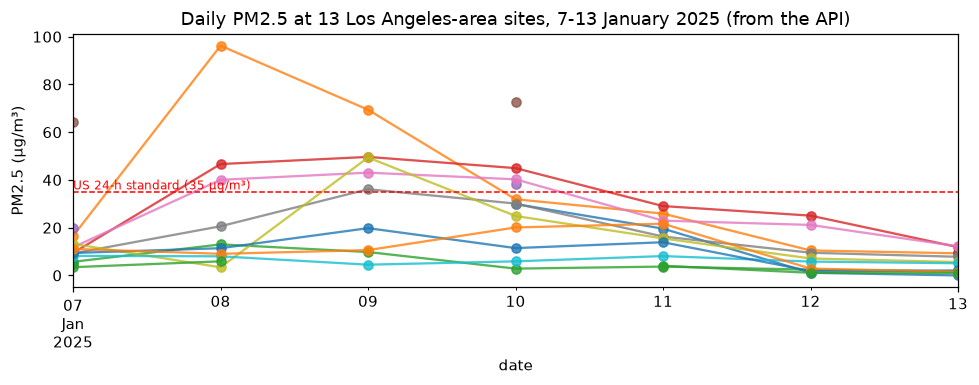

date    2025-01-07  2025-01-08  2025-01-09  2025-01-10  2025-01-11  \
count         24.0        15.0        14.0        18.0        17.0   
median         9.6        13.0        38.4        29.7        19.6   
max           64.1        99.6        74.2        72.5        29.1   

date    2025-01-12  2025-01-13  
count         17.0        25.0  
median         5.8         7.1  
max           26.1        13.0  


In [13]:
# Plot Los Angeles-area PM2.5 time series fetched from the API
la = gpd.GeoDataFrame.from_features(http.get(f"{BASE}/collections/pm25/items", params=q[4][2]).json(), crs=4326)
la["date"] = pd.to_datetime(la["date"])                    # GeoJSON carries dates as ISO 8601 text
daily = la.pivot_table(index="date", columns="site", values="pm25")
ax = daily.plot(figsize=(9, 3.6), marker="o", legend=False, alpha=0.8)
ax.axhline(35, color="red", ls="--", lw=1); ax.text(daily.index[0], 36, "US 24-h standard (35 µg/m³)", color="red", fontsize=8)
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title(f"Daily PM2.5 at {daily.shape[1]} Los Angeles-area sites, 7-13 January 2025 (from the API)")
plt.tight_layout(); plt.show()
print(la.groupby("date").pm25.agg(["count", "median", "max"]).round(1).T)


Each filter is answered by the server, so only matching features travel:

- the central-Dhaka box returned 123 unions (67 kB);
- an attribute filter returned the 81 unions of Satkhira district, and 84 of the 263 fields grow the
  BR28 rice variety;
- `datetime` selects by the collection's date column: 154 sites reported on 1 July 2025, and an
  interval plus a box returned 130 measurements from Los Angeles-area sites for 7-13 January 2025.
  An open interval (`2025-12-25T00:00:00Z/..`) matched 1,111 rows; with `limit=1` only one was sent.

The figure shows why time filters matter: that January week was the week of the Los Angeles
wildfires. Daily PM2.5 reached 99.6 µg/m³ on 8 January, and the median across sites was 38.4 µg/m³
on 9 January, above the US 24-hour standard, before falling to 5.8-7.1 µg/m³ on 12-13 January.
The `datetime` filter and the temporal extent in `/collections` were added to `create_app` while
writing this notebook: OGC API: Features Core requires servers to accept `datetime`, and the
earlier version rejected it as an unknown property.

### Errors are part of the contract

A good API fails clearly, with the right status code and a message:

In [14]:
# Probe common error cases (missing collection, bad params, unknown feature)
for path in ["/collections/rivers", "/collections/unions/items?bbox=90,23,91",
             "/collections/pm25/items?datetime=last-week", "/collections/unions/items?limit=0",
             "/collections/unions/items?colour=red", "/collections/unions/items/999999"]:
    r = http.get(BASE + path)
    print(r.status_code, f"{path:45s}", r.json().get("description", ""))


404 /collections/rivers                           No collection 'rivers'
400 /collections/unions/items?bbox=90,23,91       bbox must be minLon,minLat,maxLon,maxLat
400 /collections/pm25/items?datetime=last-week    datetime must be an RFC 3339 instant or interval, e.g. 2024-01-01T00:00:00Z or 2024-01-01T00:00:00Z/..
400 /collections/unions/items?limit=0             limit must be a positive integer and offset a non-negative integer
400 /collections/unions/items?colour=red          Unknown property 'colour'
404 /collections/unions/items/999999              No feature '999999' in 'unions'


### What a page costs

Every page is GeoJSON, so its size follows the geometry. For the unions:

In [15]:
# Measure response size and time as the items limit grows
rows = []
for limit in [10, 100, 1000, 5160]:
    t0 = time.perf_counter()
    r = http.get(f"{BASE}/collections/unions/items", params={"limit": limit})
    rows.append({"limit": limit, "MB": round(len(r.content) / 1e6, 2), "seconds": round(time.perf_counter() - t0, 2),
                 "kB per union": round(len(r.content) / 1e3 / limit, 1)})
page_cost = pd.DataFrame(rows)
page_cost


,limit,MB,seconds,kB per union
0,10,0.02,0.00,1.6
1,100,0.18,0.01,1.8
2,1000,1.93,0.03,1.9
3,5160,9.55,0.16,1.9


Each simplified union costs about 1.6-1.9 kB of GeoJSON, so the whole layer is 9.55 MB, delivered
in 0.16 s on this machine. At full resolution the same request is 301 MB (Section 7). Paging,
`bbox` filters and simplified display geometry keep responses small; serve full-resolution
geometry only to clients that need it for analysis.

## Using the service from GDAL, GeoPandas and OWSLib

The point of a standard is that clients written by others work without knowing anything about our
server. Three independent ones:

- **GDAL's OAPIF driver** (and so QGIS, ArcGIS Pro via GDAL, `ogr2ogr`): opened with `OAPIF:` plus the URL;
- **GeoPandas**, which reads a GeoJSON URL directly;
- **OWSLib**, a Python client library for OGC services.

In [16]:
# Query the feature API with GDAL/OGR and copy districts to a GeoPackage
ds = gdal.OpenEx("OAPIF:" + BASE, gdal.OF_VECTOR)
print("GDAL sees", [ds.GetLayer(i).GetName() for i in range(ds.GetLayerCount())])
lyr = ds.GetLayerByName("unions")
t0 = time.perf_counter()
print(f"unions: {lyr.GetFeatureCount():,} features, extent {[round(v, 2) for v in lyr.GetExtent()]}")
lyr.SetSpatialFilterRect(90.35, 23.70, 90.45, 23.82)
names = [f.GetField("ADM4_EN") for f in lyr]
print(f"GDAL bbox query: {len(names)} unions in central Dhaka, e.g. {sorted(set(names))[:4]} ({time.perf_counter() - t0:.1f} s)")
lyr.SetSpatialFilter(None)
lyr.SetAttributeFilter("ADM2_EN = 'Satkhira'")
print("GDAL attribute filter, Satkhira unions:", lyr.GetFeatureCount())

# ogr2ogr: copy a collection from the service into a GeoPackage, as a desktop user would
t0 = time.perf_counter()
gdal.VectorTranslate(str(OUT / "from_api.gpkg"), "OAPIF:" + BASE, layers=["districts"], format="GPKG")
copied = gpd.read_file(OUT / "from_api.gpkg")
print(f"ogr2ogr copied {len(copied)} districts to from_api.gpkg in {time.perf_counter() - t0:.1f} s")
ds = None


GDAL sees ['districts', 'unions', 'fields', 'pm25']
unions: 5,160 features, extent [88.01, 92.68, 20.59, 26.63]
GDAL bbox query: 123 unions in central Dhaka, e.g. ['Aganagar', 'Badda', 'Beraid', 'Bhatara'] (0.0 s)


GDAL attribute filter, Satkhira unions: 81
ogr2ogr copied 64 districts to from_api.gpkg in 0.1 s


In [17]:
# Read features with GeoPandas and OWSLib against the same OGC API endpoint
t0 = time.perf_counter()
gdf = gpd.read_file(f"{BASE}/collections/districts/items?limit=1000")
print(f"GeoPandas: {len(gdf)} districts, CRS {gdf.crs.to_string()}, in {time.perf_counter() - t0:.2f} s")
same = gdf.set_index("district").poverty_pct.sort_index().equals(districts.set_index("district").poverty_pct.sort_index())
print("poverty values identical to the source:", same)

oapi = Features(BASE)
print("OWSLib collections:", [c["id"] for c in oapi.collections()["collections"]])
fc = oapi.collection_items("fields", limit=500)
fields_back = gpd.GeoDataFrame.from_features(fc, crs=4326)
print(f"OWSLib: {fc['numberReturned']} fields, mean water arsenic {fields_back.WAs.mean():.3f} mg/L "
      f"(source {fields.WAs.mean():.3f})")


GeoPandas: 64 districts, CRS EPSG:4326, in 0.05 s
poverty values identical to the source: True
OWSLib collections: ['districts', 'unions', 'fields', 'pm25']
OWSLib: 263 fields, mean water arsenic 0.130 mg/L (source 0.130)


All three clients worked against the service without any configuration beyond its URL:

- GDAL found the four collections. Its bounding-box query returned the same 123 unions as our own
  request, its attribute filter the same 81 Satkhira unions, and `ogr2ogr` copied the 64 districts
  into a GeoPackage.
- GeoPandas read the 64 districts, with poverty values identical to the source.
- OWSLib listed the collections and read all 263 fields; their mean water arsenic, 0.130 mg/L,
  matches the source table.

Before this notebook `create_app` had no `/api` (OpenAPI) document, which OGC API. Features Core
requires and the landing page must link as `service-desc`; it was added along with `datetime`.

**In QGIS:** *Layer → Add Layer → Add WFS / OGC API: Features Layer*, new connection, URL = the
landing page. The collections appear as layers; QGIS sends `bbox` requests as you pan.

### A map viewer

`create_app` also serves `/viewer`, a Leaflet page that draws every collection and tile layer. It
reads each collection through the same `/items` URL as any other client.

In [18]:
# Start a combined raster+vector app and open its built-in map viewer
viewer_app = web.create_app(
    rasters={"ndvi": {"path": ndvi_path, "colormap": "RdYlGn", "rescale": (-0.1, 0.9)}},
    vectors={"counties": gpd.read_file(DATA / "00_shared" / "vector_data" / "USA" / "NY_County_GCS.shp")[["COUNTY", "geometry"]]
             .pipe(lambda g: g[g.COUNTY.isin([f"{c} County" for c in ["Onondaga", "Madison", "Cayuga", "Oswego", "Cortland"]])])},
    title="Syracuse NDVI and counties")
viewer = web.start_server(viewer_app)
display(IFrame(viewer.url + "/viewer", width="100%", height=450))


The viewer, like the other live maps in this notebook, is served by this notebook's kernel and goes
blank when the kernel stops.

## One server, many requests

A map view fires dozens of tile requests at once, often while another client downloads features.
`create_app` handles requests concurrently: features are encoded in worker threads, with geometry
written by GEOS (`shapely.to_geojson`) rather than through Python dictionaries. But threads in one
Python process share one interpreter lock (the GIL), so a CPU-heavy request still competes with
everything else in that process. Production servers therefore run several **worker processes**.

We measure tile latency alone, and while another client (`curl`, in its own process) downloads all
5,160 unions at full resolution, the heaviest request this data allows. First with the server
inside this notebook (one process, shared with the notebook itself), then with the same app run by
`uvicorn --workers 4` in separate processes.

In [19]:
# Compare tile latency alone vs during a heavy download: in-process vs uvicorn workers
import socket
import subprocess
import sys

unions_full = gpd.read_file(BD / "Shapefiles" / "bd_union_GCS.shp")[["ADM4_EN", "ADM3_EN", "ADM2_EN", "geometry"]]

def tile_latencies(base, n=60):
    out = []
    with httpx.Client() as c:
        for t in (tiles14 * 3)[:n]:
            t0 = time.perf_counter()
            c.get(f"{base}/tiles/ndvi/{t.z}/{t.x}/{t.y}.png")
            out.append((time.perf_counter() - t0) * 1000)
    return np.array(out)

def under_load(base):
    "Tile latencies alone and during a full-resolution download by another process."
    alone = tile_latencies(base)
    download = subprocess.Popen(["curl", "-s", "-o", "/dev/null", "-w", "%{size_download} %{time_total}",
                                 f"{base}/collections/unions/items?limit=10000"],
                                stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
    time.sleep(0.1)
    busy = tile_latencies(base)
    size, seconds = download.communicate()[0].split()
    return alone, busy, int(size) / 1e6, float(seconds)

# 1) the server inside this notebook
inproc = web.start_server(web.create_app(
    rasters={"ndvi": {"path": ndvi_path, "colormap": "RdYlGn", "rescale": (-0.1, 0.9)}},
    vectors={"unions": unions_full}))                     # full resolution: 7.8 million vertices
results = {"in notebook, 1 process": under_load(inproc.url)}
inproc.stop()

# 2) the same app in a module, served by 4 uvicorn worker processes
app_code = "\n".join([
    "import geopandas as gpd",
    "import geolattice.web as web",
    f"unions = gpd.read_file(r'{(BD / 'Shapefiles' / 'bd_union_GCS.shp').resolve()}')[['ADM4_EN', 'ADM3_EN', 'ADM2_EN', 'geometry']]",
    f"app = web.create_app(rasters={{'ndvi': {{'path': r'{ndvi_path.resolve()}', 'colormap': 'RdYlGn', 'rescale': (-0.1, 0.9)}}}},",
    "                     vectors={'unions': unions})", ""])
(OUT / "unions_app.py").write_text(app_code)
with socket.socket() as sock:
    sock.bind(("127.0.0.1", 0)); port = sock.getsockname()[1]
workers = subprocess.Popen([sys.executable, "-m", "uvicorn", "unions_app:app", "--port", str(port), "--workers", "4",
                            "--log-level", "warning"], cwd=OUT, stderr=subprocess.DEVNULL)
base = f"http://127.0.0.1:{port}"
time.sleep(3)
for _ in range(300):                                       # wait until the workers answer
    try:
        if http.get(base + "/collections/unions/items?limit=1").status_code == 200:
            break
    except httpx.HTTPError:
        pass
    time.sleep(0.5)
time.sleep(10)                                             # let every worker finish loading the data
results["uvicorn, 4 worker processes"] = under_load(base)
workers.terminate(); workers.wait()

rows = {}
for name, (alone, busy, mb_, s_) in results.items():
    rows[(name, "tiles alone")] = [np.median(alone), np.percentile(alone, 95), alone.max()]
    rows[(name, "during download")] = [np.median(busy), np.percentile(busy, 95), busy.max()]
    print(f"{name}: the download of {mb_:.0f} MB took {s_:.1f} s")
pd.DataFrame(rows, index=["median ms", "95th percentile ms", "max ms"]).round(1)


in notebook, 1 process: the download of 301 MB took 3.0 s
uvicorn, 4 worker processes: the download of 301 MB took 3.0 s


in notebook, 1 process                  \
                              tiles alone during download   
median ms                            31.9            31.4   
95th percentile ms                   38.6            40.8   
max ms                               40.0          1615.6   

                   uvicorn, 4 worker processes                  
                                   tiles alone during download  
median ms                                 34.8            34.1  
95th percentile ms                        67.0            65.7  
max ms                                   105.4           115.1

Downloading the full-resolution unions (301 MB) took about 3 s either way. The median tile time
barely changed, but the tail did. With the server inside the notebook, the slowest tile waited
1.6 s while the download was being encoded: the encoding thread and the tile thread take turns on
one interpreter lock. With four uvicorn worker processes, the tile requests were answered by
other processes and the slowest took 115 ms. Each worker holds its own copy of the data, so memory
grows with the number of workers.

Two fixes in `create_app` came out of this measurement. Feature responses used to be encoded on
the event loop, three times over (`to_json`, `json.loads`, `json.dumps`); while one large request
was being encoded, every other request waited; in our tests a 1,000-union page took 4.9 s. Features are now
encoded once, with GEOS, in a worker thread that yields between chunks; the same page took about
0.7 s, and the server kept answering tiles meanwhile.

## Vector tiles as one file: PMTiles

Vector tiles cut features into the XYZ grid, simplified for each zoom, and the browser styles them.
A **PMTiles** archive stores a whole tile set in one file with an index at the front; a map reads the
header, then fetches each tile with an HTTP range request. Any static host serves it: no tile
server, no database. We write the unions as PMTiles, read the archive over HTTP with the `pmtiles`
Python reader, and count the bytes.

In [20]:
# Write unions to PMTiles and fetch individual tiles over HTTP range requests
t0 = time.perf_counter()
pm_path = write_pmtiles(OUT / "unions.pmtiles", unions[["ADM4_EN", "ADM3_EN", "ADM2_EN", "geometry"]],
                        layer="unions", minzoom=5, maxzoom=12)
print(f"unions.pmtiles: {Path(pm_path).stat().st_size / 1e6:.1f} MB, written in {time.perf_counter() - t0:.1f} s")

def http_source(url, server):
    "pmtiles byte source over HTTP range requests."
    def get_bytes(offset, length):
        return http.get(url, headers={"Range": f"bytes={offset}-{offset + length - 1}"}).content
    return get_bytes

static.reset()
reader = pmr.Reader(http_source(f"{static.url}/unions.pmtiles", static))
header, meta = reader.header(), reader.metadata()
print(f"opened: {static.stats['requests']} requests, {static.stats['bytes'] / 1e3:.1f} kB")
print({k: header[k] for k in ("min_zoom", "max_zoom", "addressed_tiles_count", "tile_contents_count", "tile_compression")})
print("layers:", [l["id"] for l in meta.get("vector_layers", [])])

rows = []
for z in [6, 8, 10, 12]:
    t = web.lonlat_to_tile(90.40, 23.78, z)
    static.reset()
    data = reader.get(z, t.x, t.y)
    rows.append({"zoom": z, "tile": f"{z}/{t.x}/{t.y}", "tile kB": round(len(data) / 1e3, 1),
                 "requests": static.stats["requests"], "kB transferred": round(static.stats["bytes"] / 1e3, 1)})
pd.DataFrame(rows)


unions.pmtiles: 7.9 MB, written in 3.6 s
opened: 3 requests, 2.0 kB
{'min_zoom': 5, 'max_zoom': 12, 'addressed_tiles_count': 2881, 'tile_contents_count': 2877, 'tile_compression': <Compression.GZIP: 2>}
layers: ['unions']


,zoom,tile,tile kB,requests,kB transferred
0,6,6/48/27,262.7,3,268.5
1,8,8/192/110,127.3,3,133.1
2,10,10/769/442,18.2,3,24.0
3,12,12/3076/1769,4.3,3,10.0


The archive is 7.9 MB for all 5,160 unions at zooms 5-12, smaller than the 9.55 MB GeoJSON of the
same simplified layer, and it carries every zoom level. Opening it cost 3 requests and 2.0 kB (the
header, the root directory and the metadata). A tile then costs its own size plus a directory read:
263 kB for a whole-country tile at zoom 6, falling to 4.3 kB at zoom 12, where a tile covers a few
unions. This simple reader fetches directories again for every tile, about 6 kB each time; the
browser's `pmtiles` library caches them.

A MapLibre page displays the archive with the `pmtiles` JavaScript protocol. The page and the file
sit side by side on the static server, which is exactly how they would be published on S3 or GitHub
Pages.

In [21]:
# Write a MapLibre + PMTiles HTML page and serve it from the static server
page = '''<!DOCTYPE html><html><head><meta charset="utf-8"><title>Bangladesh unions (PMTiles)</title>
<meta name="viewport" content="width=device-width, initial-scale=1">
<link href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css" rel="stylesheet">
<script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
<script src="https://unpkg.com/pmtiles@3.2.1/dist/pmtiles.js"></script>
<style>html,body,#map{height:100%;margin:0}</style></head><body><div id="map"></div><script>
const protocol = new pmtiles.Protocol();
maplibregl.addProtocol("pmtiles", protocol.tile);
const archive = "pmtiles://" + new URL("unions.pmtiles", location.href).href;
const map = new maplibregl.Map({container: "map", center: [90.3, 23.75], zoom: 6.5, style: {version: 8,
  sources: {base: {type: "raster", tileSize: 256, attribution: "&copy; OpenStreetMap contributors",
                   tiles: ["https://tile.openstreetmap.org/{z}/{x}/{y}.png"]},
            unions: {type: "vector", url: archive}},
  layers: [{id: "base", type: "raster", source: "base", paint: {"raster-opacity": 0.6}},
           {id: "fill", type: "fill", source: "unions", "source-layer": "unions",
            paint: {"fill-color": ["match", ["get", "ADM2_EN"], "Dhaka", "#d95f02", "Satkhira", "#1b9e77", "#7570b3"],
                    "fill-opacity": 0.35}},
           {id: "line", type: "line", source: "unions", "source-layer": "unions",
            paint: {"line-color": "#333", "line-width": 0.4}}]}});
map.addControl(new maplibregl.NavigationControl());
map.on("click", "fill", e => new maplibregl.Popup().setLngLat(e.lngLat)
  .setHTML(`<b>${e.features[0].properties.ADM4_EN}</b><br>${e.features[0].properties.ADM3_EN}, ${e.features[0].properties.ADM2_EN}`).addTo(map));
</script></body></html>'''
(OUT / "unions_pmtiles.html").write_text(page)
display(IFrame(f"{static.url}/unions_pmtiles.html", width="100%", height=450))


Click a union for its name. Dhaka district is orange and Satkhira green; the colours are set in the
browser from tile attributes, so restyling needs no new tiles.

## From a notebook to production

`create_app` and `static_server` are teaching and prototyping tools. For production, the same
patterns are served by dedicated software:

| Need | Production tools | `geolattice.web` equivalent here |
|---|---|---|
| Dynamic raster tiles from COGs and STAC | **TiTiler** (FastAPI, rio-tiler), GeoServer, MapServer | `create_app(rasters=...)` |
| OGC API: Features | **pygeoapi**, GeoServer, ldproxy, QGIS Server | `create_app(vectors=...)` |
| Vector tiles from PostGIS | **Martin**, pg_tileserv, Tegola | PMTiles (static) |
| Static tiles and PMTiles | S3 / Azure Blob / GCS + CDN (CloudFront, Cloudflare), GitHub Pages | `make_xyz_tiles`, `write_pmtiles`, `static_server` |

Checklist before a service goes public:

- **HTTPS** and a stable domain; set `cors` to the sites that may use the service.
- **Caching:** `Cache-Control` headers and a CDN in front of tiles; tiles are the same for every user.
- **Limits:** a maximum page size (`max_limit`) and rate limiting, so one client cannot exhaust the server.
- **Data preparation:** COGs with overviews, simplified geometry for display, spatial indexes.
- **Monitoring:** request logs, latency percentiles and error rates.
- **Authentication** when data are not public (API keys or OAuth in front of the service; Notebook 08_06).
- **Standards:** check OGC conformance with the OGC test suite (TEAM Engine) before announcing an OGC API.

Notebook 08_06 builds custom APIs with FastAPI, which can mount a `create_app` service as one part
(`app.mount("/gis", create_app(...))`); Notebook 08_10 packages services in Docker.

In [22]:
# Stop all background servers and list output files
for server in [tile_server, api, viewer, static, files_srv]:
    server.stop()
print("servers stopped; outputs:", sorted(p.name for p in OUT.iterdir()),
      f"{sum(f.stat().st_size for f in OUT.rglob('*') if f.is_file()) / 1e6:.1f} MB")


servers stopped; outputs: ['__pycache__', 'from_api.gpkg', 'ndvi_tiles', 'unions.pmtiles', 'unions_app.py', 'unions_pmtiles.html'] 19.8 MB


## Summary and exercises

**Key ideas**

- XYZ tiles and TileJSON are the common language of web maps; OGC API: Features is the standard for
  feature access, with paging, `bbox`, attribute filters and `datetime`, described in OpenAPI.
- Static pyramids are fastest and need no server, but grow fourfold per zoom; dynamic servers render
  from the source on request and need COGs with overviews to be efficient over the network.
- A service is only useful if others' clients work with it: test with GDAL, QGIS and OWSLib.
- One process serves tiles and features together only if heavy requests do not block light ones.
- PMTiles publishes vector tiles as one static file read with range requests.

**What we measured**

- Static tiles: 3.0 ms median per tile, but 22.2 million tiles to cover Bangladesh to zoom 18.
- Dynamic tiles: 34 ms median from a local file; zoomed-out tiles from a COG read 0.82 MB against
  10.0 MB from a plain GeoTIFF.
- The OGC API service answered bbox, attribute and `datetime` queries, and GDAL, GeoPandas and OWSLib
  read it unchanged.
- During a 301 MB download, the slowest tile took 1.6 s with one process and 115 ms with four worker processes.
- PMTiles: 7.9 MB for all unions and zooms 5-12; opening costs 2 kB, a zoom-12 tile 4.3 kB.
- Fixes made to `geolattice.web` along the way:
  - `/api` and `datetime`;
  - timestamp encoding;
  - faster, non-blocking feature encoding;
  - overview reads in `render_tile`;
  - start-up checks of raster settings;
  - `start_server`;
  - `static_server(subprocess=True)`.

**Exercises**

1. Add the July and September NDVI as two tile layers of one `create_app` and open `/viewer`. How
   many tiles does a full-screen view at zoom 13 request? (Watch the server log with `log_level="info"`.)
2. Serve `stack_none_1.tif` (no compression) next to the COG and repeat the bytes-per-tile table.
3. Publish `fields` with a `date` column (assign a sampling date to each field) and query a month with
   `datetime`.
4. Use `ogr2ogr` (`gdal.VectorTranslate`) to copy only the Barisal unions from the service, using
   `where` and a spatial filter, and compare the transfer with the full layer.
5. Write the district poverty layer as PMTiles and style it as a choropleth in the MapLibre page with
   a `step` expression on `poverty_pct`.

**References**

- OGC API, Features, Part 1: Core (OGC 17-069r4). https://docs.ogc.org/is/17-069r4/17-069r4.html
- OGC Two Dimensional Tile Matrix Set and OGC API: Tiles. https://ogcapi.ogc.org/tiles/
- TileJSON specification. https://github.com/mapbox/tilejson-spec
- PMTiles specification. https://github.com/protomaps/PMTiles
- Cloud-Optimized GeoTIFF. https://cogeo.org
- TiTiler, pygeoapi and Martin documentation. https://developmentseed.org/titiler/, https://pygeoapi.io, https://maplibre.org/martin/